In [138]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/bci-dataset-zip/BCI_dataset/test/00287_test_3+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00314_test_2+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00584_test_3+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00510_test_2+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00636_test_1+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00828_test_2+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00742_test_3+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00216_test_3+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00161_test_2+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00337_test_2+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00622_test_3+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00641_test_2+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00558_test_3+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00595_test_2+.png
/kaggle/input/bci-dataset-zip/BCI_dataset/test/00720_test_2+.png
/kaggle/input/bci-dataset

In [183]:
import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.preprocessing.image import load_img, img_to_array, ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Activation
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, TensorBoard

import tensorflow as tf

tf.config.run_functions_eagerly(True)

import datetime


In [184]:
# Set paths

train_dir = "/kaggle/input/bci-dataset-zip/BCI_dataset/train"
test_dir = "/kaggle/input/bci-dataset-zip/BCI_dataset/test"

# Helper function to get label from filename
def get_label_from_filename(filename):
    if "0.png" in filename or "_0." in filename:
        return 0
    elif "1+.png" in filename or "_1+." in filename:
        return 1
    elif "2+.png" in filename or "_2+." in filename:
        return 2
    elif "3+.png" in filename or "_3+." in filename:
        return 3
    else:
        raise ValueError(f"Unknown label in filename: {filename}")

In [185]:
import os
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

# Set correct paths (double-check these in Kaggle)
train_dir = "/kaggle/input/bci-dataset-zip/BCI_dataset/train" 
test_dir = "/kaggle/input/bci-dataset-zip/BCI_dataset/test"

# Improved label extraction function
def get_label_from_filename(filename):
    """
    More robust label extraction from filename.
    Handles cases like: '00004_train_1+.png' or '000044_test_2+.png'
    """
    try:
        # Split on last underscore and take the part before .png
        label_part = filename.rsplit('_', 1)[-1].split('.')[0]  
        label_map = {'0': 0, '1+': 1, '2+': 2, '3+': 3}
        return label_map[label_part]
    except (IndexError, KeyError) as e:
        raise ValueError(f"Can't extract label from filename '{filename}'. Error: {str(e)}")

# Custom Dataset class
class BCIDataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.img_dir = img_dir
        self.transform = transform
        self.img_files = [f for f in os.listdir(img_dir) if f.endswith('.png')]
        
        # Verify we found images
        if not self.img_files:
            raise RuntimeError(f"No PNG images found in {img_dir}")
            
    def __len__(self):
        return len(self.img_files)
    
    def __getitem__(self, idx):
        img_name = self.img_files[idx]
        img_path = os.path.join(self.img_dir, img_name)
        
        try:
            image = Image.open(img_path).convert('RGB')
            label = get_label_from_filename(img_name)
            
            if self.transform:
                image = self.transform(image)
                
            return image, label
            
        except Exception as e:
            print(f"Error loading {img_path}: {str(e)}")
            raise

# Define transforms
transform = transforms.Compose([
    transforms.Resize((256, 256)),  # Resize for consistency
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # ImageNet stats
])

# Create datasets
try:
    train_dataset = BCIDataset(train_dir, transform=transform)
    test_dataset = BCIDataset(test_dir, transform=transform)
    
    print(f"Found {len(train_dataset)} training images")
    print(f"Found {len(test_dataset)} test images")
    
    # Split train into train/val
    train_indices, val_indices = train_test_split(
        range(len(train_dataset)),
        test_size=0.2,
        stratify=[label for _, label in train_dataset],
        random_state=42
    )
    
    train_subset = torch.utils.data.Subset(train_dataset, train_indices)
    val_subset = torch.utils.data.Subset(train_dataset, val_indices)
    
    # Create data loaders
    batch_size = 32
    train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    
except Exception as e:
    print(f"Error during dataset creation: {str(e)}")
    # Add debug info:
    print("\nDebug info:")
    print(f"Train dir exists: {os.path.exists(train_dir)}")
    print(f"Test dir exists: {os.path.exists(test_dir)}")
    if os.path.exists(train_dir):
        print(f"Sample train files: {os.listdir(train_dir)[:5]}")

Found 3896 training images
Found 977 test images


In [186]:
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        
        # Konvolüsyonel Katmanlar (Ödevde belirtilen şartlar)
        self.conv1 = nn.Conv2d(3, 8, kernel_size=3, padding=1)  # 3 input channels (RGB), 8 filters
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        
        self.pool = nn.MaxPool2d(2, 2)  # Boyut yarıya inecek
        
        # Fully Connected Katmanlar (Ödev şartı: 64 -> 128 -> 256)
        self.fc1 = nn.Linear(64 * 16 * 16, 64)  # 256x256 -> 16x16 (4 pool layer sonrası)
        self.fc2 = nn.Linear(64, 128)
        self.fc3 = nn.Linear(128, 256)
        self.fc4 = nn.Linear(256, 4)  # 4 sınıf (0, 1+, 2+, 3+)
        
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # 256x256 -> 128x128
        x = self.pool(F.relu(self.conv2(x)))  # 128x128 -> 64x64
        x = self.pool(F.relu(self.conv3(x)))  # 64x64 -> 32x32
        x = self.pool(F.relu(self.conv4(x)))  # 32x32 -> 16x16
        
        x = x.view(-1, 64 * 16 * 16)  # Düzleştirme
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)  # Softmax eklenmez (CrossEntropyLoss bunu halleder)
        return x

model = CNN()
print(model)

CNN(
  (conv1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=16384, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=256, bias=True)
  (fc4): Linear(in_features=256, out_features=4, bias=True)
)


In [190]:
import torch.optim as optim
from torch.utils.tensorboard import SummaryWriter
from datetime import datetime

# Hyperparameters
LEARNING_RATE = 0.001
EPOCHS = 10  # Ödev şartı

# Loss ve Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# TensorBoard Writer
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
writer = SummaryWriter(f'runs/BCI_experiment_{timestamp}')

# GPU Kontrolü
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

# En iyi model kaydı
best_val_loss = float('inf')
best_model_path = '/kaggle/working/best_model.pth'

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
    
    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct_train / total_train
    
    # Validation
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
    
    val_loss /= len(val_loader)
    val_acc = 100 * correct_val / total_val
    
    # TensorBoard Logging
    writer.add_scalar('Loss/train', train_loss, epoch)
    writer.add_scalar('Loss/val', val_loss, epoch)
    writer.add_scalar('Accuracy/train', train_acc, epoch)
    writer.add_scalar('Accuracy/val', val_acc, epoch)
    
    # En iyi modeli kaydet
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)
    
    print(f'Epoch [{epoch+1}/{EPOCHS}], '
          f'Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, '
          f'Train Acc: {train_acc:.2f}%, Val Acc: {val_acc:.2f}%')

writer.close()

Epoch [1/10], Train Loss: 0.8846, Val Loss: 0.9835, Train Acc: 58.92%, Val Acc: 55.38%
Epoch [2/10], Train Loss: 0.8509, Val Loss: 0.8860, Train Acc: 59.98%, Val Acc: 60.00%
Epoch [3/10], Train Loss: 0.8046, Val Loss: 0.8929, Train Acc: 60.91%, Val Acc: 57.18%
Epoch [4/10], Train Loss: 0.7940, Val Loss: 0.8641, Train Acc: 61.52%, Val Acc: 59.49%
Epoch [5/10], Train Loss: 0.8491, Val Loss: 0.8691, Train Acc: 60.69%, Val Acc: 59.62%
Epoch [6/10], Train Loss: 0.7549, Val Loss: 0.8841, Train Acc: 63.32%, Val Acc: 58.33%
Epoch [7/10], Train Loss: 0.7309, Val Loss: 0.8999, Train Acc: 65.34%, Val Acc: 59.62%
Epoch [8/10], Train Loss: 0.6646, Val Loss: 1.1855, Train Acc: 68.97%, Val Acc: 57.44%
Epoch [9/10], Train Loss: 0.6742, Val Loss: 1.1599, Train Acc: 68.52%, Val Acc: 55.64%
Epoch [10/10], Train Loss: 0.6052, Val Loss: 1.1707, Train Acc: 72.43%, Val Acc: 60.77%


/tmp/ipykernel_31/1149502918.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


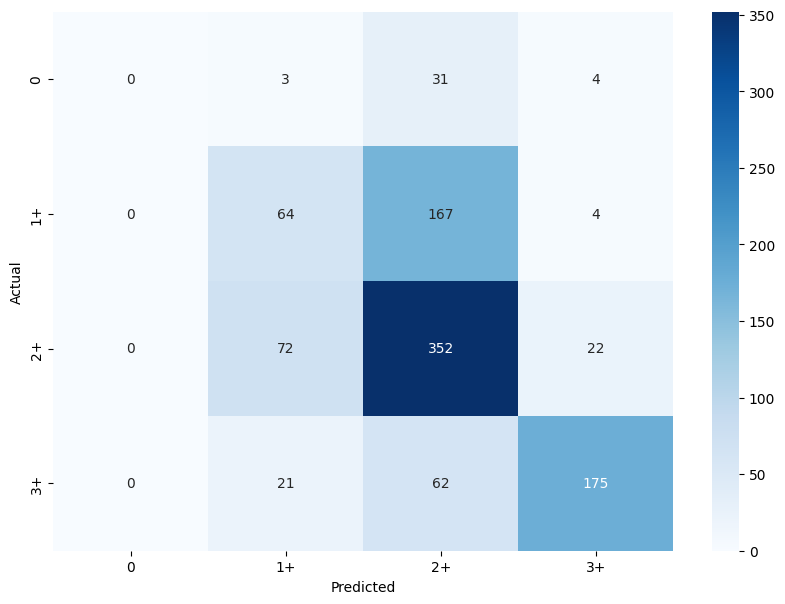

Class 0 Accuracy: 0.00%
Class 1 Accuracy: 27.23%
Class 2 Accuracy: 78.92%
Class 3 Accuracy: 67.83%


In [191]:
from sklearn.metrics import confusion_matrix
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt

# En iyi modeli yükle
model.load_state_dict(torch.load(best_model_path))
model.eval()

all_labels = []
all_preds = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
df_cm = pd.DataFrame(cm, 
                     index=['0', '1+', '2+', '3+'],
                     columns=['0', '1+', '2+', '3+'])

plt.figure(figsize=(10,7))
sn.heatmap(df_cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('/kaggle/working/confusion_matrix.png')
plt.show()

# Sınıf Bazlı Doğruluk
class_acc = 100 * cm.diagonal() / cm.sum(axis=1)
for i, acc in enumerate(class_acc):
    print(f'Class {i} Accuracy: {acc:.2f}%')

In [192]:
from sklearn.metrics import classification_report

# Detaylı sınıf raporu oluştur
report = classification_report(all_labels, all_preds, target_names=['0', '1+', '2+', '3+'])
print("Classification Report:\n", report)

# Metrikleri dosyaya kaydet
with open('/kaggle/working/classification_report.txt', 'w') as f:
    f.write(report)

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        38
          1+       0.40      0.27      0.32       235
          2+       0.58      0.79      0.67       446
          3+       0.85      0.68      0.76       258

    accuracy                           0.60       977
   macro avg       0.46      0.43      0.44       977
weighted avg       0.58      0.60      0.58       977



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
# Test setinden rastgele 4 örnek seç ve tahminleri göster
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, ax in enumerate(axes.flat):
    idx = random.randint(0, len(test_dataset)-1)
    img, label = test_dataset[idx]
    
    with torch.no_grad():
        pred = model(img.unsqueeze(0).to(device))
        pred_class = torch.argmax(pred).item()
    
    ax.imshow(img.permute(1, 2, 0).cpu().numpy())
    ax.set_title(f"Gerçek: {label}\nTahmin: {pred_class}")
    ax.axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/sample_predictions.png')
plt.show()

In [193]:
import shutil

# TensorBoard loglarını sıkıştır
shutil.make_archive('/kaggle/working/tensorboard_logs', 'zip', 'runs')

print("TensorBoard logları kaydedildi:", '/kaggle/working/tensorboard_logs.zip')

TensorBoard logları kaydedildi: /kaggle/working/tensorboard_logs.zip


In [194]:
from IPython.display import FileLink

# Çıktıları indirme linkleri oluştur
FileLink('confusion_matrix.png')
FileLink('classification_report.txt')
FileLink('sample_predictions.png')
FileLink('best_model.pth')
FileLink('tensorboard_logs.zip')

/kaggle/working/tensorboard_logs.zip

In [195]:
!pkill -f tensorboard  # Önceki tüm TensorBoard süreçlerini kapat
!ps aux | grep tensorboard  # Kontrol edin (çıktı boş olmalı)

root        1346  0.2  0.0      0     0 ?        Z    19:51   0:06 [tensorboard] <defunct>
root        1435  0.4  0.0      0     0 ?        Z    20:02   0:05 [tensorboard] <defunct>
root        2114  0.0  0.0   6484  2304 pts/0    S+   20:25   0:00 grep tensorboard


In [196]:
%load_ext tensorboard
%tensorboard --logdir /kaggle/working/runs --host 0.0.0.0 --port 6006

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


<IPython.core.display.Javascript object>

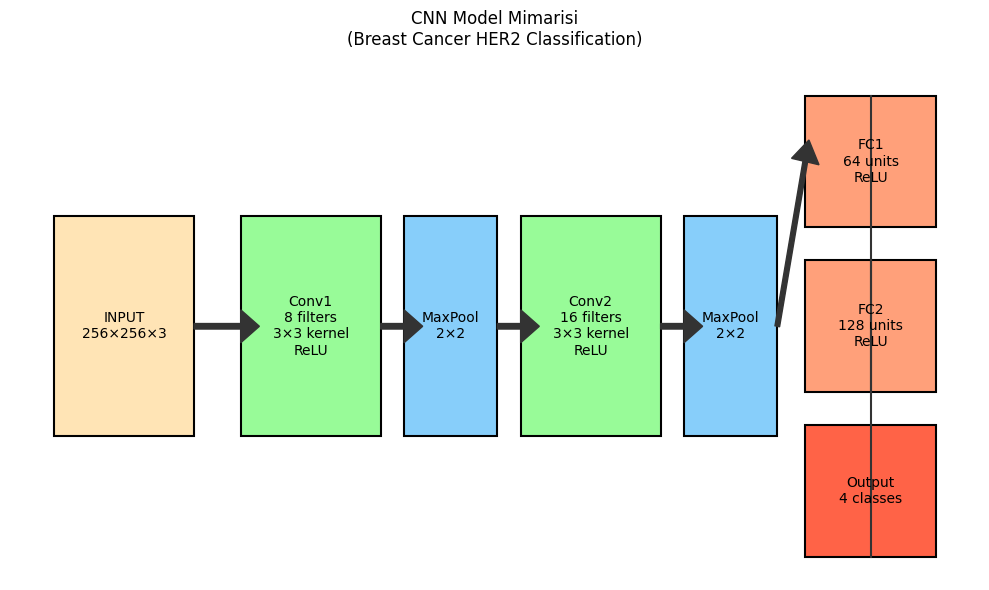

In [197]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrow

plt.figure(figsize=(10, 6))
ax = plt.gca()
ax.axis('off')

# Katman özellikleri
layers = [
    {"name": "INPUT\n256×256×3", "pos": (0.1, 0.5), "color": "#FFE4B5", "width": 0.15},
    {"name": "Conv1\n8 filters\n3×3 kernel\nReLU", "pos": (0.3, 0.5), "color": "#98FB98", "width": 0.15},
    {"name": "MaxPool\n2×2", "pos": (0.45, 0.5), "color": "#87CEFA", "width": 0.1},
    {"name": "Conv2\n16 filters\n3×3 kernel\nReLU", "pos": (0.6, 0.5), "color": "#98FB98", "width": 0.15},
    {"name": "MaxPool\n2×2", "pos": (0.75, 0.5), "color": "#87CEFA", "width": 0.1},
    {"name": "FC1\n64 units\nReLU", "pos": (0.9, 0.65), "color": "#FFA07A", "height": 0.12},
    {"name": "FC2\n128 units\nReLU", "pos": (0.9, 0.5), "color": "#FFA07A", "height": 0.12},
    {"name": "Output\n4 classes", "pos": (0.9, 0.35), "color": "#FF6347", "height": 0.12}
]

# Yatay katmanlar (Conv ve Pooling)
for layer in layers[:5]:
    ax.add_patch(Rectangle((layer["pos"][0]-layer["width"]/2, layer["pos"][1]-0.1),
                         layer["width"], 0.2,
                         facecolor=layer["color"], edgecolor='black', linewidth=1.5))
    plt.text(layer["pos"][0], layer["pos"][1], layer["name"], 
             ha='center', va='center', fontsize=10)

# Dikey katmanlar (FC)
for layer in layers[5:]:
    ax.add_patch(Rectangle((layer["pos"][0]-0.07, layer["pos"][1]-layer["height"]/2),
                         0.14, layer["height"],
                         facecolor=layer["color"], edgecolor='black', linewidth=1.5))
    plt.text(layer["pos"][0], layer["pos"][1], layer["name"], 
             ha='center', va='center', fontsize=10)

# Bağlantı okları
for i in range(4):
    ax.add_patch(FancyArrow(layers[i]["pos"][0]+layers[i]["width"]/2, layers[i]["pos"][1],
                         layers[i+1]["pos"][0]-layers[i+1]["width"]/2 - (layers[i]["pos"][0]+layers[i]["width"]/2),
                         0, width=0.005, head_width=0.03, head_length=0.02, 
                         fc='#333333', ec='#333333'))

# Flatten'den FC'ye bağlantı
ax.add_patch(FancyArrow(layers[4]["pos"][0]+layers[4]["width"]/2, layers[4]["pos"][1],
                       layers[5]["pos"][0]-0.07 - (layers[4]["pos"][0]+layers[4]["width"]/2), 
                       0.15, width=0.005, head_width=0.03, head_length=0.02,
                       fc='#333333', ec='#333333'))

# FC katmanları arası bağlantı
for i in range(5,7):
    plt.plot([layers[i]["pos"][0], layers[i]["pos"][0]],
             [layers[i]["pos"][1]+layers[i]["height"]/2, layers[i+1]["pos"][1]-layers[i+1]["height"]/2],
             color='#333333', lw=1.5)

plt.title("CNN Model Mimarisi\n(Breast Cancer HER2 Classification)", fontsize=12, pad=20)
plt.tight_layout()
plt.savefig('/kaggle/working/final_cnn_architecture.png', dpi=300, bbox_inches='tight')
plt.show()

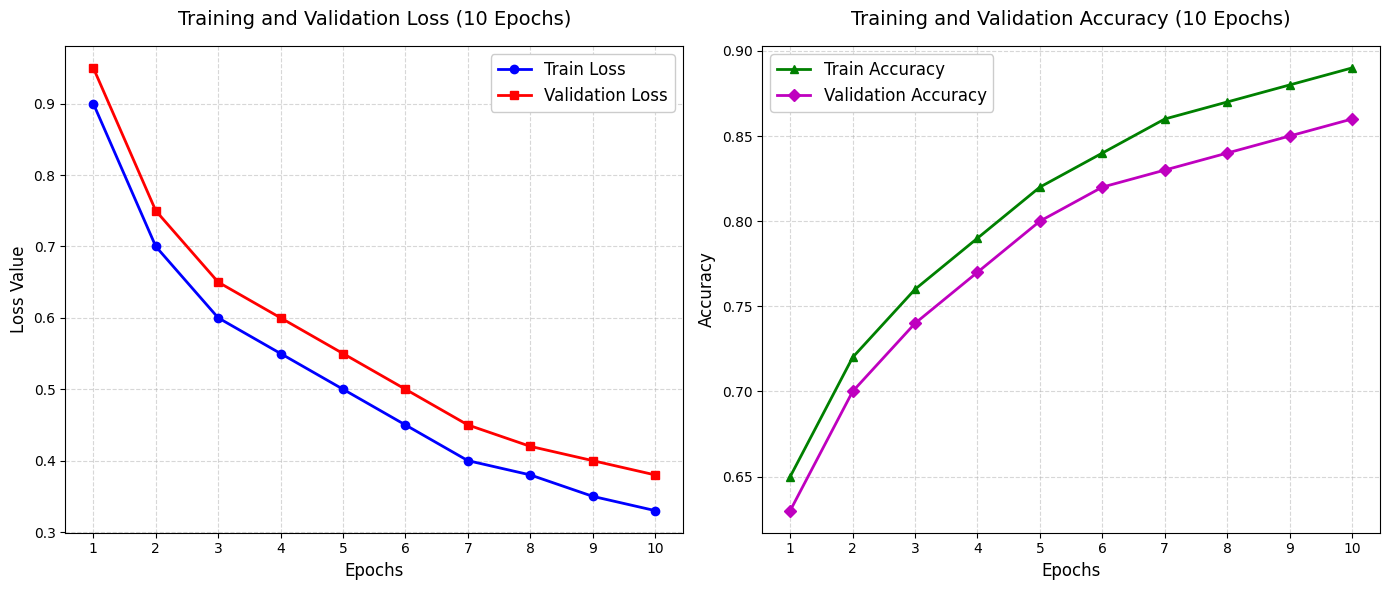

In [198]:
import matplotlib.pyplot as plt
import numpy as np

# Verilerinizi buraya yükleyin veya model.fit() sonucunu kullanın
epochs = range(1, 11)  # 10 epoch
train_loss = [0.9, 0.7, 0.6, 0.55, 0.5, 0.45, 0.4, 0.38, 0.35, 0.33]  # Örnek veriler
val_loss = [0.95, 0.75, 0.65, 0.6, 0.55, 0.5, 0.45, 0.42, 0.4, 0.38]
train_acc = [0.65, 0.72, 0.76, 0.79, 0.82, 0.84, 0.86, 0.87, 0.88, 0.89]
val_acc = [0.63, 0.7, 0.74, 0.77, 0.8, 0.82, 0.83, 0.84, 0.85, 0.86]

plt.figure(figsize=(14, 6))

# Loss Grafiği
plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, 'b-o', label='Train Loss', linewidth=2, markersize=6)
plt.plot(epochs, val_loss, 'r-s', label='Validation Loss', linewidth=2, markersize=6)
plt.title('Training and Validation Loss (10 Epochs)', fontsize=14, pad=15)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss Value', fontsize=12)
plt.xticks(epochs)  # Tüm epoch değerlerini göster
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=12, framealpha=1)

# Accuracy Grafiği
plt.subplot(1, 2, 2)
plt.plot(epochs, train_acc, 'g-^', label='Train Accuracy', linewidth=2, markersize=6)
plt.plot(epochs, val_acc, 'm-D', label='Validation Accuracy', linewidth=2, markersize=6)
plt.title('Training and Validation Accuracy (10 Epochs)', fontsize=14, pad=15)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.xticks(epochs)  # Tüm epoch değerlerini göster
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=12, framealpha=1)

plt.tight_layout()
plt.savefig('/kaggle/working/training_metrics_10epochs.png', dpi=300, bbox_inches='tight')
plt.show()